Dataset Shape: (732, 12)

First 5 Rows:
   Unnamed: 0                              College_Name       State    UG_fee  \
0           0    Indian Institute of Technology Madras   Tamil nadu     75116   
1           1  College of Engineering, Anna University   Tamil nadu     50000   
2           2              NIT Trichy, Tiruchirappalli   Tamil nadu  1,49,250   
3           3          Vellore Institute of Technology   Tamil nadu  1,98,000   
4           4     SRM Engineering College, Kanchipuram   Tamil nadu  2,60,000   

     PG_fee Rating Academic Accommodation Faculty Infrastructure Placement  \
0     23070    8.7        9           7.9     8.7            8.8       8.8   
1     50000    8.4      8.7           7.7     8.1            8.7       8.3   
2     99250    8.5      8.6           7.8     8.2            8.7       8.8   
3  1,83,000    8.3      8.3             8     7.8            8.9       8.5   
4  1,70,000    7.2      6.5           6.6     6.9            7.6       7.1   

  So

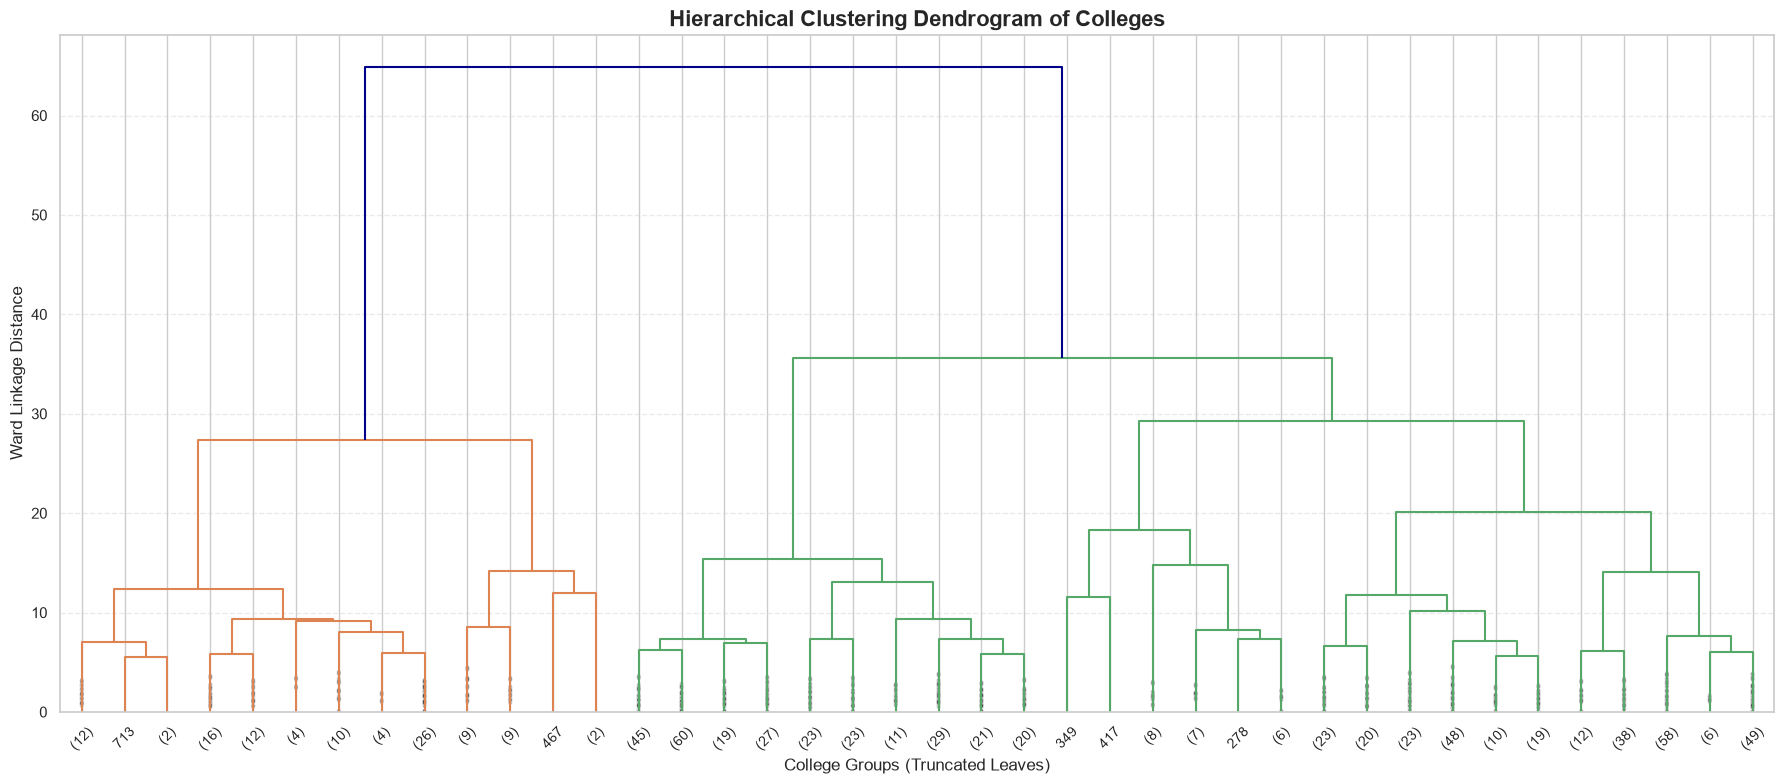


Number of Clusters: 3

Number of Colleges in Each Cluster:
Cluster
0    330
1    108
2    278
Name: count, dtype: int64

Sample Cluster Assignments:
                               College_Name  Cluster
0    Indian Institute of Technology Madras         0
1  College of Engineering, Anna University         0
2              NIT Trichy, Tiruchirappalli         0
3          Vellore Institute of Technology         0
4     SRM Engineering College, Kanchipuram         1
5               SSN College of Engineering         0
6             SASTRA University, Thanjavur         0
7              P.S.G College of Technology         0
8       Thiagarajar College of Engineering         0
9       Coimbatore Institute of Technology         2


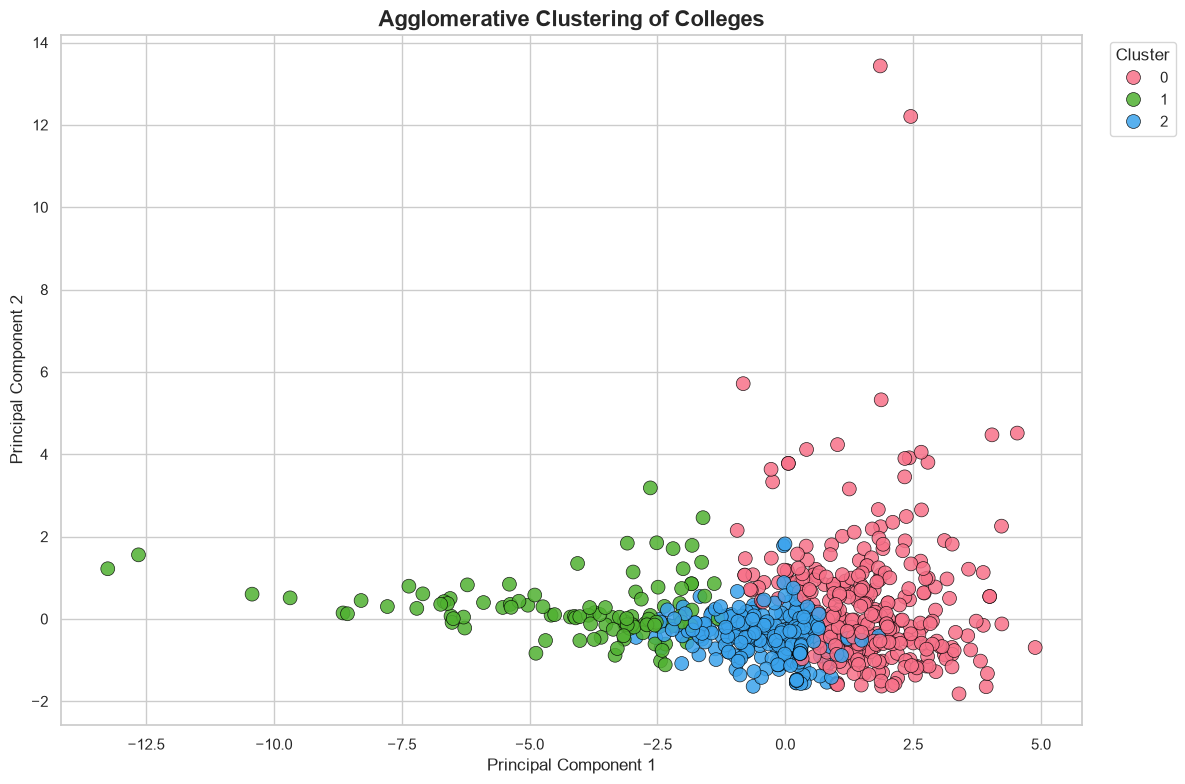


Silhouette Score: 0.1670
A higher silhouette score generally indicates better-separated clusters.

Average Feature Values for Each Cluster:
            UG_fee     PG_fee  Rating  Academic  Accommodation  Faculty  \
Cluster                                                                   
0        176942.04  116917.19    8.24      8.44           7.76     8.28   
1        100362.38   86729.18    6.41      6.96           6.11     6.83   
2         81347.90   70612.82    7.67      7.95           7.19     7.84   

         Infrastructure  Placement  Social_Life  
Cluster                                          
0                  8.47       8.07         8.30  
1                  6.71       5.51         6.57  
2                  7.79       7.26         7.84  


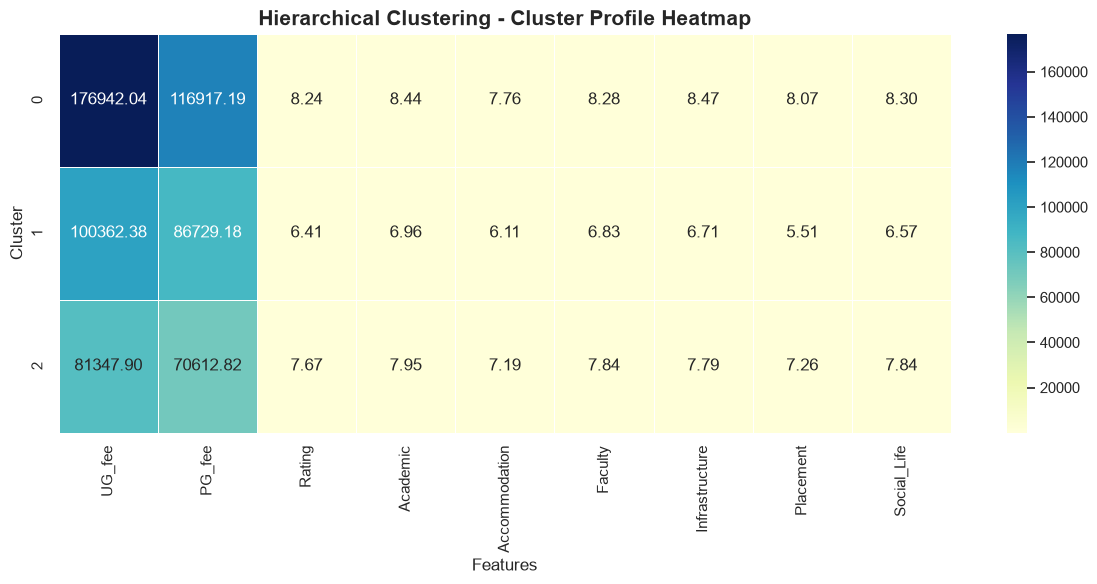


Cluster results saved to Hierarchical_College_Clusters.csv


In [1]:

# Hierarchical Clustering on Colleges_Dataset.csv
# Building Dendrogram and Applying Agglomerative Clustering

# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

sns.set_theme(style="whitegrid")

# Step 2: Load the dataset
df = pd.read_csv("Colleges_Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# Step 3: Select numerical features
features = [
    "UG_fee",
    "PG_fee",
    "Rating",
    "Academic",
    "Accommodation",
    "Faculty",
    "Infrastructure",
    "Placement",
    "Social_Life"
]

X = df[features].copy()

# Step 4: Clean numerical data
for col in features:
    X[col] = pd.to_numeric(
        X[col].astype(str)
        .str.replace(",", "", regex=False)
        .str.strip()
        .replace("--", np.nan),
        errors="coerce"
    )

# Remove columns that contain no valid numeric data
X = X.dropna(axis=1, how="all")

# Remove rows where all selected features are missing
X = X.dropna(axis=0, how="all")

# Keep corresponding college names and row indices
college_names = (
    df.loc[X.index, "College_Name"]
    .fillna("Unknown College")
    .reset_index(drop=True)
)

# Step 5: Handle missing values
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X)

# Step 6: Standardize the data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("\nFeatures Used:", list(X.columns))
print("Processed Data Shape:", X_scaled.shape)

# Step 7: Build the linkage matrix
# Ward linkage minimizes within-cluster variance.
# Use all colleges to construct the dendrogram.
linkage_matrix = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

# Step 8: Draw a colourful dendrogram
plt.figure(figsize=(18, 8))

dendrogram(
    linkage_matrix,
    truncate_mode="lastp",
    p=40,
    leaf_rotation=45,
    leaf_font_size=10,
    show_contracted=True,
    color_threshold=None,
    above_threshold_color="darkblue"
)

plt.title(
    "Hierarchical Clustering Dendrogram of Colleges",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("College Groups (Truncated Leaves)", fontsize=12)
plt.ylabel("Ward Linkage Distance", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# Step 9: Apply Agglomerative Clustering
# Change n_clusters after inspecting the dendrogram.
optimal_k = 3

model = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric="euclidean",
    linkage="ward"
)

cluster_labels = model.fit_predict(X_scaled)

# Step 10: Store cluster assignments
results = pd.DataFrame({
    "College_Name": college_names,
    "Cluster": cluster_labels
})

print(f"\nNumber of Clusters: {optimal_k}")
print("\nNumber of Colleges in Each Cluster:")
print(results["Cluster"].value_counts().sort_index())

print("\nSample Cluster Assignments:")
print(results.head(10))

# Step 11: Visualize clusters using PCA
# PCA projects the data onto two dimensions for plotting.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plot_df = pd.DataFrame({
    "PCA1": X_pca[:, 0],
    "PCA2": X_pca[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(12, 8))

palette = sns.color_palette("husl", optimal_k)

sns.scatterplot(
    data=plot_df,
    x="PCA1",
    y="PCA2",
    hue="Cluster",
    palette=palette,
    s=100,
    alpha=0.85,
    edgecolor="black",
    linewidth=0.5
)

plt.title(
    "Agglomerative Clustering of Colleges",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.legend(title="Cluster", bbox_to_anchor=(1.02, 1),
           loc="upper left")
plt.tight_layout()
plt.show()

# Step 12: Evaluate clustering using Silhouette Score
if 1 < len(np.unique(cluster_labels)) < len(X_scaled):
    score = silhouette_score(X_scaled, cluster_labels)
    print(f"\nSilhouette Score: {score:.4f}")
    print("A higher silhouette score generally indicates "
          "better-separated clusters.")

# Step 13: Display average feature values by cluster
profile_data = pd.DataFrame(X_imputed, columns=X.columns)
profile_data["Cluster"] = cluster_labels

cluster_profile = profile_data.groupby("Cluster").mean().round(2)

print("\nAverage Feature Values for Each Cluster:")
print(cluster_profile)

# Step 14: Colourful cluster profile heatmap
plt.figure(figsize=(12, 6))

sns.heatmap(
    cluster_profile,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.7
)

plt.title(
    "Hierarchical Clustering - Cluster Profile Heatmap",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

# Step 15: Save cluster assignments
results.to_csv("Hierarchical_College_Clusters.csv", index=False)

print("\nCluster results saved to Hierarchical_College_Clusters.csv")
